Saving archive (2).zip to archive (2).zip

Datasets found:
Cleaned_NSUT.xlsx
FINAL_ITO_DATA.xlsx
final_dataset.csv


DATASET: Cleaned_NSUT.xlsx
Usable rows: 1431
Features: 59
Persistence validation MAE: 41.07
Training: CatBoost_1
  New best validation MAE: 22.94
Training: CatBoost_2
  New best validation MAE: 21.33
Training: CatBoost_3
Training: XGBoost_1
Training: XGBoost_2
Training: XGBoost_3
Training: ExtraTrees_1
  New best validation MAE: 21.08
Training: ExtraTrees_2
  New best validation MAE: 20.49
Training: ExtraTrees_3
  New best validation MAE: 20.37
Training: HistGradientBoosting_1
Training: HistGradientBoosting_2


DATASET: FINAL_ITO_DATA.xlsx
Usable rows: 1431
Features: 59
Persistence validation MAE: 37.71
Training: CatBoost_1
  New best validation MAE: 19.06
Training: CatBoost_2
  New best validation MAE: 18.35
Training: CatBoost_3
Training: XGBoost_1
Training: XGBoost_2
Training: XGBoost_3
Training: ExtraTrees_1
  New best validation MAE: 17.03
Training: ExtraTrees_2
  Ne

,Dataset,Model,Validation_MAE,Validation_RMSE,Baseline_Validation_MAE
0,FINAL_ITO_DATA.xlsx,ExtraTrees_3,16.95,22.34,37.71
1,FINAL_ITO_DATA.xlsx,ExtraTrees_2,17.00,22.35,37.71
2,FINAL_ITO_DATA.xlsx,ExtraTrees_1,17.03,22.08,37.71
3,FINAL_ITO_DATA.xlsx,CatBoost_2,18.35,23.12,37.71
4,FINAL_ITO_DATA.xlsx,XGBoost_3,18.70,23.82,37.71
5,FINAL_ITO_DATA.xlsx,XGBoost_2,18.82,23.68,37.71
6,FINAL_ITO_DATA.xlsx,HistGradientBoosting_1,18.84,23.73,37.71
7,FINAL_ITO_DATA.xlsx,CatBoost_1,19.06,24.04,37.71
8,FINAL_ITO_DATA.xlsx,CatBoost_3,19.06,24.05,37.71
9,FINAL_ITO_DATA.xlsx,XGBoost_1,19.06,23.69,37.71



BEST MODEL
Dataset: FINAL_ITO_DATA.xlsx
Model: ExtraTrees_3
Validation MAE: 16.95

FINAL TEST RESULTS


,Model,Test MAE,Test RMSE
0,Persistence Baseline,32.05,46.57
1,ExtraTrees_3,16.25,24.11



Best model test MAE: 16.25
Best model test RMSE: 24.11

The selected model beats the persistence baseline.


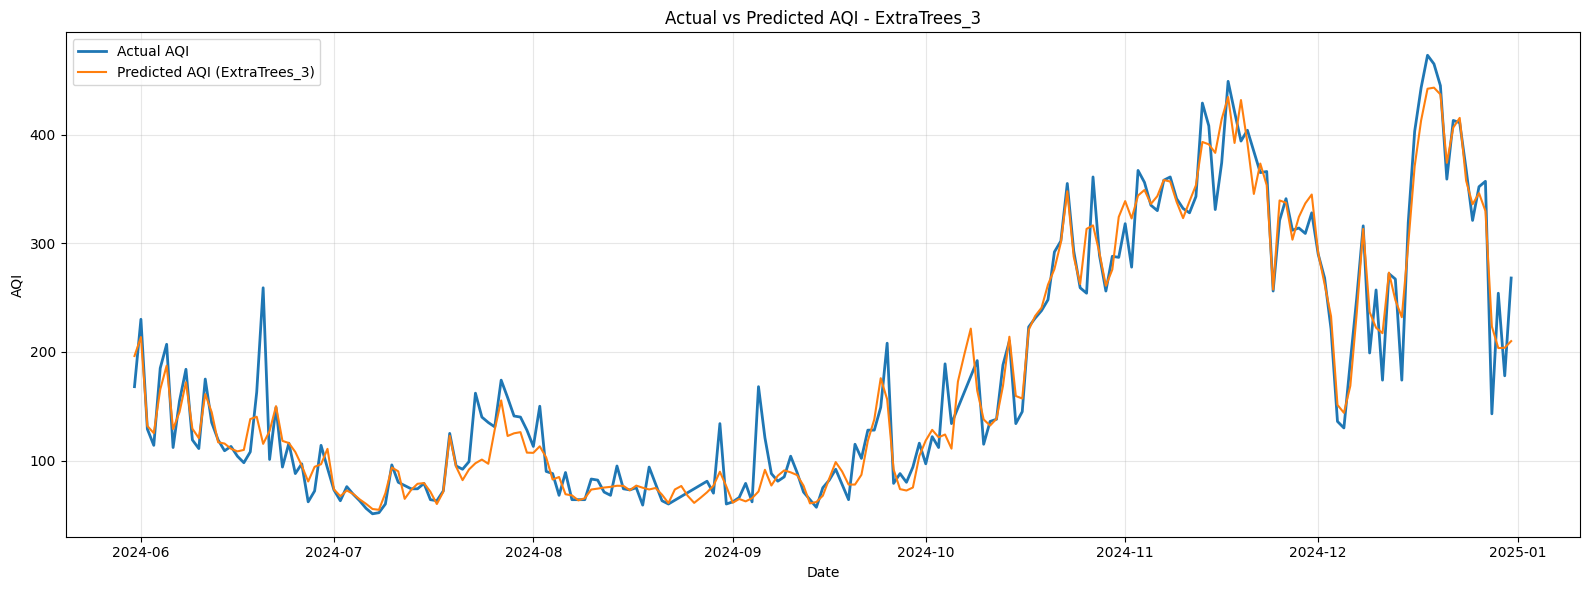

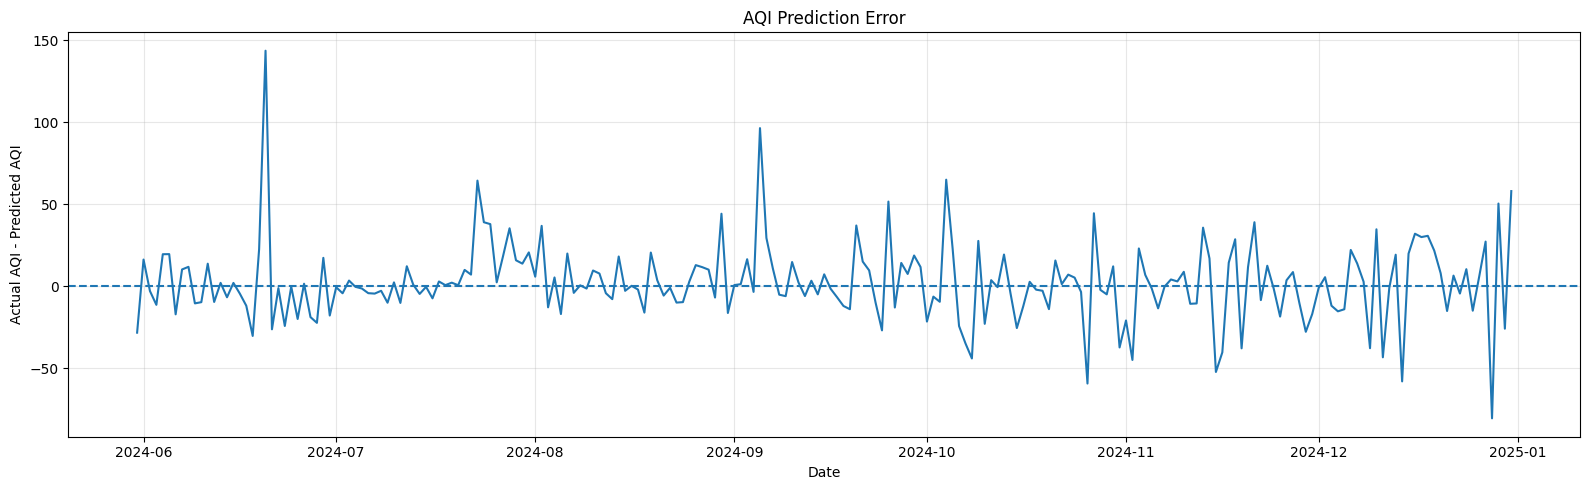

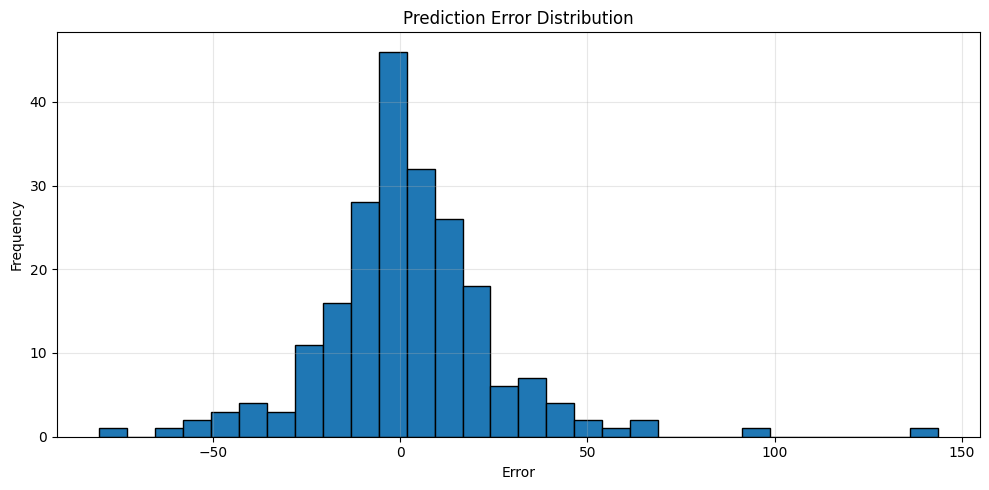


TOP 20 IMPORTANT FEATURES


,Feature,Importance
0,PM2.5,0.2409
1,PM10,0.1959
2,AQI_previous_1_day,0.1435
3,AQI_previous_mean_3_days,0.0716
4,PM2.5_previous_1_day,0.0664
5,AQI_previous_min_3_days,0.0591
6,PM10_previous_1_day,0.0479
7,AQI_previous_max_3_days,0.0336
8,AQI_previous_mean_7_days,0.0268
9,AQI_previous_2_day,0.0195


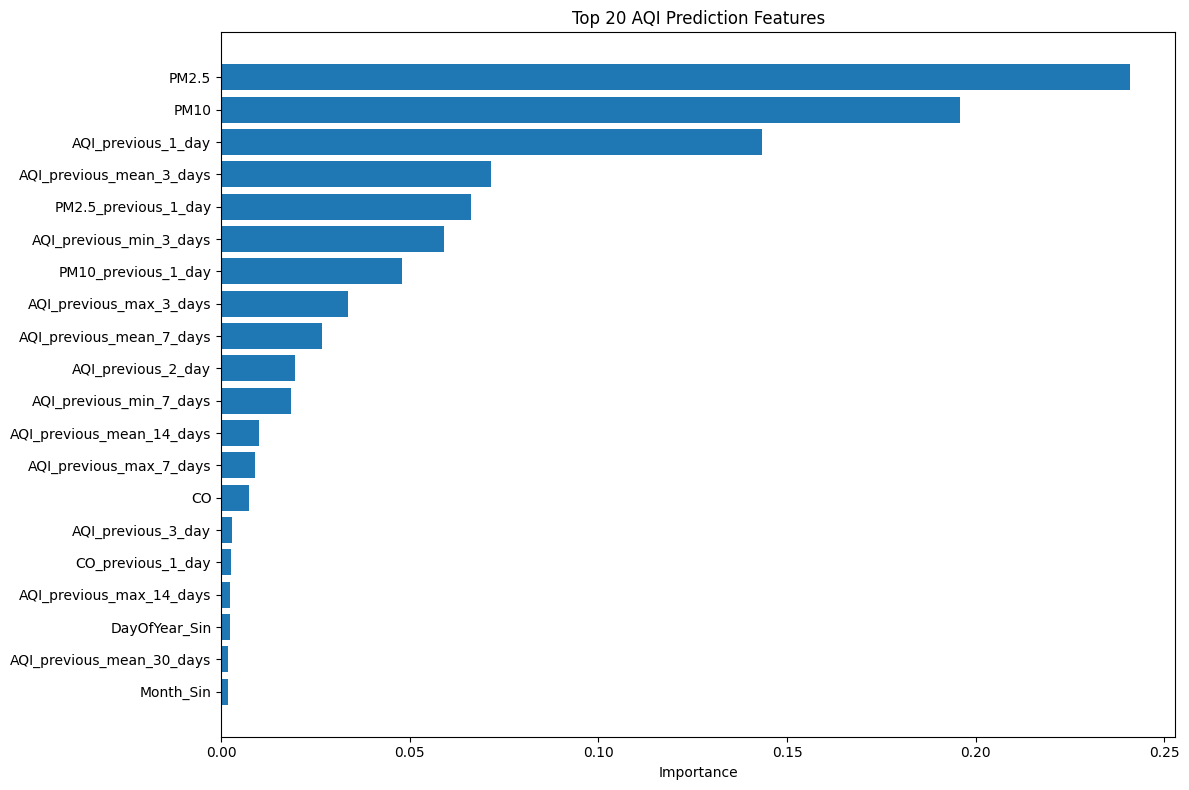


Model and reports saved.
Selected dataset: FINAL_ITO_DATA.xlsx
Selected model: ExtraTrees_3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# AQI PREDICTION USING POLLUTANTS + PREVIOUS AQI
# Complete Google Colab code
# ============================================================

!pip -q install catboost xgboost openpyxl

import os
import zipfile
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

from google.colab import files
from IPython.display import display

warnings.filterwarnings("ignore")
np.random.seed(42)

# ============================================================
# 1. UPLOAD AND EXTRACT DATASET
# ============================================================

uploaded = files.upload()

uploaded_name = list(uploaded.keys())[0]

work_dir = "/content/aqi_prediction"
os.makedirs(work_dir, exist_ok=True)

uploaded_path = os.path.join(work_dir, uploaded_name)

with open(uploaded_path, "wb") as f:
    f.write(uploaded[uploaded_name])

if uploaded_name.lower().endswith(".zip"):

    extract_dir = os.path.join(work_dir, "data")
    os.makedirs(extract_dir, exist_ok=True)

    with zipfile.ZipFile(uploaded_path, "r") as z:
        z.extractall(extract_dir)

    dataset_files = []

    for root, dirs, filenames in os.walk(extract_dir):
        for filename in filenames:
            if filename.lower().endswith((".xlsx", ".xls", ".csv")):
                dataset_files.append(
                    os.path.join(root, filename)
                )

else:
    dataset_files = [uploaded_path]

print("\nDatasets found:")

for path in dataset_files:
    print(os.path.basename(path))

# ============================================================
# 2. READ DATASETS
# ============================================================

def read_dataset(path):

    if path.lower().endswith(".csv"):
        data = pd.read_csv(path)

    else:
        data = pd.read_excel(path)

    return data


# ============================================================
# 3. CREATE TIMESTAMP
# ============================================================

def prepare_dataset(data):

    data = data.copy()

    data.columns = [
        str(col).strip()
        for col in data.columns
    ]

    if "Timestamp" in data.columns:

        data["Timestamp"] = pd.to_datetime(
            data["Timestamp"],
            errors="coerce"
        )

    elif all(
        col in data.columns
        for col in ["Year", "Month", "Date"]
    ):

        data["Timestamp"] = pd.to_datetime(
            {
                "year": data["Year"],
                "month": data["Month"],
                "day": data["Date"]
            },
            errors="coerce"
        )

    else:
        raise ValueError(
            "Dataset must contain Timestamp or Year, Month and Date."
        )

    data = data.dropna(
        subset=["Timestamp"]
    ).copy()

    data["Timestamp"] = (
        data["Timestamp"].dt.normalize()
    )

    required_columns = [
        "AQI",
        "PM2.5",
        "PM10",
        "NO2",
        "SO2",
        "CO",
        "Ozone"
    ]

    missing = [
        col for col in required_columns
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )

    numeric_cols = required_columns.copy()

    for col in ["Holidays_Count", "Days"]:
        if col in data.columns:
            numeric_cols.append(col)

    for col in numeric_cols:
        data[col] = pd.to_numeric(
            data[col],
            errors="coerce"
        )

    # If duplicate dates exist, average them
    data = (
        data.groupby("Timestamp", as_index=False)[numeric_cols]
        .mean()
        .sort_values("Timestamp")
        .reset_index(drop=True)
    )

    # Reindex to daily frequency
    data = data.set_index("Timestamp")

    full_dates = pd.date_range(
        data.index.min(),
        data.index.max(),
        freq="D"
    )

    data = data.reindex(full_dates)
    data.index.name = "Timestamp"

    # Fill input features using past values only
    pollutant_cols = [
        "PM2.5",
        "PM10",
        "NO2",
        "SO2",
        "CO",
        "Ozone"
    ]

    for col in pollutant_cols:
        data[col] = data[col].ffill()

    # AQI target is not filled
    return data


# ============================================================
# 4. FEATURE ENGINEERING
# ============================================================

def create_features(data):

    data = data.copy()

    pollutant_cols = [
        "PM2.5",
        "PM10",
        "NO2",
        "SO2",
        "CO",
        "Ozone"
    ]

    feature_df = pd.DataFrame(
        index=data.index
    )

    # Current-day pollutant values
    # These are assumed to be available when AQI is predicted.

    for col in pollutant_cols:
        feature_df[col] = data[col]

    # Previous AQI values
    for lag in [1, 2, 3, 5, 7, 14, 21, 30]:

        feature_df[
            f"AQI_previous_{lag}_day"
        ] = data["AQI"].shift(lag)

    # Previous pollutant values
    for col in pollutant_cols:

        for lag in [1, 3, 7]:

            feature_df[
                f"{col}_previous_{lag}_day"
            ] = data[col].shift(lag)

    # Previous AQI rolling statistics
    # Shift by 1 first, so today's target AQI is never included.

    previous_aqi = data["AQI"].shift(1)

    for window in [3, 7, 14, 30]:

        feature_df[
            f"AQI_previous_mean_{window}_days"
        ] = previous_aqi.rolling(
            window=window,
            min_periods=window
        ).mean()

        feature_df[
            f"AQI_previous_std_{window}_days"
        ] = previous_aqi.rolling(
            window=window,
            min_periods=window
        ).std()

        feature_df[
            f"AQI_previous_max_{window}_days"
        ] = previous_aqi.rolling(
            window=window,
            min_periods=window
        ).max()

        feature_df[
            f"AQI_previous_min_{window}_days"
        ] = previous_aqi.rolling(
            window=window,
            min_periods=window
        ).min()

    # AQI trend
    feature_df["AQI_change_1_day"] = (
        data["AQI"].shift(1)
        - data["AQI"].shift(2)
    )

    feature_df["AQI_change_7_days"] = (
        data["AQI"].shift(1)
        - data["AQI"].shift(8)
    )

    # Calendar features
    feature_df["Month"] = data.index.month
    feature_df["DayOfWeek"] = data.index.dayofweek
    feature_df["DayOfYear"] = data.index.dayofyear

    feature_df["Month_Sin"] = np.sin(
        2 * np.pi * data.index.month / 12
    )

    feature_df["Month_Cos"] = np.cos(
        2 * np.pi * data.index.month / 12
    )

    feature_df["DayOfYear_Sin"] = np.sin(
        2 * np.pi * data.index.dayofyear / 365.25
    )

    feature_df["DayOfYear_Cos"] = np.cos(
        2 * np.pi * data.index.dayofyear / 365.25
    )

    # Optional dataset columns
    if "Holidays_Count" in data.columns:
        feature_df["Holidays_Count"] = (
            data["Holidays_Count"]
        )

    if "Days" in data.columns:
        feature_df["Days"] = data["Days"]

    # Target: same-day AQI
    target = data["AQI"]

    # Combine
    model_df = feature_df.copy()
    model_df["Target_AQI"] = target

    model_df = model_df.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Drop missing feature history or missing AQI targets
    model_df = model_df.dropna().copy()

    X = model_df.drop(
        columns=["Target_AQI"]
    )

    y = model_df["Target_AQI"]

    return X, y, model_df.index


# ============================================================
# 5. DEFINE MODELS AND PARAMETERS
# ============================================================

model_configs = {

    "CatBoost_1": CatBoostRegressor(
        iterations=700,
        depth=6,
        learning_rate=0.03,
        loss_function="MAE",
        l2_leaf_reg=5,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    ),

    "CatBoost_2": CatBoostRegressor(
        iterations=1000,
        depth=5,
        learning_rate=0.025,
        loss_function="MAE",
        l2_leaf_reg=7,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    ),

    "CatBoost_3": CatBoostRegressor(
        iterations=600,
        depth=7,
        learning_rate=0.03,
        loss_function="MAE",
        l2_leaf_reg=8,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    ),

    "XGBoost_1": XGBRegressor(
        n_estimators=700,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=3,
        reg_lambda=5,
        objective="reg:squarederror",
        eval_metric="mae",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost_2": XGBRegressor(
        n_estimators=900,
        max_depth=3,
        learning_rate=0.025,
        subsample=0.9,
        colsample_bytree=0.9,
        min_child_weight=2,
        reg_lambda=8,
        objective="reg:squarederror",
        eval_metric="mae",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost_3": XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=10,
        objective="reg:squarederror",
        eval_metric="mae",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees_1": ExtraTreesRegressor(
        n_estimators=500,
        max_features=0.8,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees_2": ExtraTreesRegressor(
        n_estimators=500,
        max_features=0.9,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees_3": ExtraTreesRegressor(
        n_estimators=500,
        max_features=1.0,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting_1": HistGradientBoostingRegressor(
        max_iter=400,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=2,
        random_state=42
    ),

    "HistGradientBoosting_2": HistGradientBoostingRegressor(
        max_iter=500,
        learning_rate=0.03,
        max_leaf_nodes=20,
        l2_regularization=5,
        random_state=42
    )
}


# ============================================================
# 6. TRAIN / VALIDATION / TEST
# ============================================================

all_results = []
all_test_predictions = []
best_validation_mae = float("inf")

best_model = None
best_model_name = None
best_dataset_name = None
best_features = None
best_test_predictions = None
best_test_actual = None
best_test_dates = None

for dataset_path in dataset_files:

    dataset_name = os.path.basename(dataset_path)

    print("\n")
    print("=" * 70)
    print("DATASET:", dataset_name)
    print("=" * 70)

    raw_df = read_dataset(dataset_path)
    data = prepare_dataset(raw_df)

    X, y, dates = create_features(data)

    print("Usable rows:", len(X))
    print("Features:", X.shape[1])

    # Chronological 70:15:15 split
    n = len(X)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    X_train = X.iloc[:train_end]
    y_train = y.iloc[:train_end]

    X_val = X.iloc[train_end:val_end]
    y_val = y.iloc[train_end:val_end]

    X_test = X.iloc[val_end:]
    y_test = y.iloc[val_end:]

    dates_test = dates[val_end:]

    # Persistence baseline: predict today's AQI using yesterday's AQI
    baseline_val = X_val[
        "AQI_previous_1_day"
    ].to_numpy()

    baseline_test = X_test[
        "AQI_previous_1_day"
    ].to_numpy()

    baseline_val_mae = mean_absolute_error(
        y_val,
        baseline_val
    )

    baseline_test_mae = mean_absolute_error(
        y_test,
        baseline_test
    )

    baseline_test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            baseline_test
        )
    )

    print(
        f"Persistence validation MAE: "
        f"{baseline_val_mae:.2f}"
    )

    # Test all models
    for model_name, model in model_configs.items():

        print("Training:", model_name)

        model.fit(
            X_train,
            y_train
        )

        val_pred = model.predict(X_val)

        val_mae = mean_absolute_error(
            y_val,
            val_pred
        )

        val_rmse = np.sqrt(
            mean_squared_error(
                y_val,
                val_pred
            )
        )

        # Save validation result
        all_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Validation_MAE": val_mae,
            "Validation_RMSE": val_rmse,
            "Baseline_Validation_MAE": baseline_val_mae
        })

        # Select best model using validation MAE only
        if val_mae < best_validation_mae:

            best_validation_mae = val_mae
            best_model_name = model_name
            best_dataset_name = dataset_name
            best_features = X.columns.tolist()

            best_model = model

            best_test_predictions = model.predict(
                X_test
            )

            best_test_actual = y_test.to_numpy()
            best_test_dates = dates_test

            best_test_baseline = baseline_test.copy()

            best_test_mae = mean_absolute_error(
                y_test,
                best_test_predictions
            )

            best_test_rmse = np.sqrt(
                mean_squared_error(
                    y_test,
                    best_test_predictions
                )
            )

            best_test_baseline_mae = baseline_test_mae
            best_test_baseline_rmse = baseline_test_rmse

            print(
                f"  New best validation MAE: "
                f"{val_mae:.2f}"
            )

# ============================================================
# 7. DISPLAY MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    "Validation_MAE"
).reset_index(drop=True)

print("\nMODEL COMPARISON BY VALIDATION MAE")
display(results_df.round(2))

print("\nBEST MODEL")
print("Dataset:", best_dataset_name)
print("Model:", best_model_name)
print("Validation MAE:", round(best_validation_mae, 2))

# ============================================================
# 8. FINAL TEST RESULTS
# ============================================================

final_results = pd.DataFrame({

    "Model": [
        "Persistence Baseline",
        best_model_name
    ],

    "Test MAE": [
        best_test_baseline_mae,
        best_test_mae
    ],

    "Test RMSE": [
        best_test_baseline_rmse,
        best_test_rmse
    ]
})

print("\nFINAL TEST RESULTS")
display(final_results.round(2))

print("\nBest model test MAE:", round(best_test_mae, 2))
print("Best model test RMSE:", round(best_test_rmse, 2))

if best_test_mae < best_test_baseline_mae:
    print("\nThe selected model beats the persistence baseline.")
else:
    print(
        "\nThe selected model does not beat the persistence baseline."
    )

# ============================================================
# 9. ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(figsize=(16, 6))

plt.plot(
    best_test_dates,
    best_test_actual,
    label="Actual AQI",
    linewidth=2
)

plt.plot(
    best_test_dates,
    best_test_predictions,
    label=f"Predicted AQI ({best_model_name})",
    linewidth=1.5
)

plt.title(
    f"Actual vs Predicted AQI - {best_model_name}"
)

plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 10. PREDICTION ERROR GRAPH
# ============================================================

errors = (
    best_test_actual
    - best_test_predictions
)

plt.figure(figsize=(16, 5))

plt.plot(
    best_test_dates,
    errors
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("AQI Prediction Error")
plt.xlabel("Date")
plt.ylabel("Actual AQI - Predicted AQI")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 11. ERROR DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    errors,
    bins=30,
    edgecolor="black"
)

plt.title("Prediction Error Distribution")
plt.xlabel("Error")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 12. FEATURE IMPORTANCE
# ============================================================

if hasattr(best_model, "feature_importances_"):

    importance_df = pd.DataFrame({
        "Feature": best_features,
        "Importance": best_model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    print("\nTOP 20 IMPORTANT FEATURES")
    display(importance_df.head(20).round(4))

    top_features = importance_df.head(20).sort_values(
        "Importance"
    )

    plt.figure(figsize=(12, 8))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"]
    )

    plt.title("Top 20 AQI Prediction Features")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

# ============================================================
# 13. SAVE BEST MODEL AND RESULTS
# ============================================================

output_dir = "/content/aqi_prediction/results"
os.makedirs(output_dir, exist_ok=True)

# Save selected model
model_path = os.path.join(
    output_dir,
    "best_aqi_model.pkl"
)

with open(model_path, "wb") as f:
    pickle.dump(best_model, f)

# Save validation comparison
results_df.to_csv(
    os.path.join(
        output_dir,
        "model_validation_comparison.csv"
    ),
    index=False
)

# Save final metrics
final_results.to_csv(
    os.path.join(
        output_dir,
        "final_test_metrics.csv"
    ),
    index=False
)

# Save predictions
predictions_df = pd.DataFrame({
    "Date": best_test_dates,
    "Actual_AQI": best_test_actual,
    "Predicted_AQI": best_test_predictions,
    "Previous_AQI_Baseline": best_test_baseline,
    "Error": errors
})

predictions_df.to_csv(
    os.path.join(
        output_dir,
        "test_predictions.csv"
    ),
    index=False
)

# Save feature list
with open(
    os.path.join(
        output_dir,
        "feature_columns.pkl"
    ),
    "wb"
) as f:
    pickle.dump(best_features, f)

# Save model information
with open(
    os.path.join(
        output_dir,
        "model_summary.txt"
    ),
    "w"
) as f:

    f.write("AQI PREDICTION MODEL\n")
    f.write("===================\n\n")

    f.write(f"Dataset: {best_dataset_name}\n")
    f.write(f"Model: {best_model_name}\n")
    f.write(
        f"Validation MAE: {best_validation_mae:.4f}\n"
    )
    f.write(
        f"Test MAE: {best_test_mae:.4f}\n"
    )
    f.write(
        f"Test RMSE: {best_test_rmse:.4f}\n"
    )
    f.write(
        f"Baseline Test MAE: "
        f"{best_test_baseline_mae:.4f}\n"
    )
    f.write(
        f"Baseline Test RMSE: "
        f"{best_test_baseline_rmse:.4f}\n"
    )

# Zip all outputs
zip_path = "/content/aqi_prediction_results.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for root, dirs, filenames in os.walk(output_dir):

        for filename in filenames:

            full_path = os.path.join(
                root,
                filename
            )

            z.write(
                full_path,
                arcname=filename
            )

print("\nModel and reports saved.")
print("Selected dataset:", best_dataset_name)
print("Selected model:", best_model_name)

files.download(zip_path)



